<a href="https://colab.research.google.com/github/Bianca-21-bit/Relat-rio/blob/main/Modelo_Random_Forest_(no_python).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# <> ----------------------------------------------------
# <> Verificando se o pacote está instalado
# <> o símbolo % é para executar no bash (executar no terminal)
%pip show pycaret

In [2]:
# <> -------------------------------------------------------
# <> Instalando o PyCaret 3.3.2 no Python 3.13 do Colab
# <> --no-deps => instala o PyCaret sem rebaixar numpy, pandas e scipy do Colab
%pip install -q pycaret==3.3.2 --no-deps

# <> dependências do PyCaret (as que já existem no Colab são mantidas)
# <> scikit-learn 1.5.2 e jobliv 1.3.2 são as versões compatíveis com o PyCaret 3.3.2
%pip install -q "scikit-learn==1.5.2" "joblib==1.3.2" "schemdraw==0.15" \
    pyod imbalanced-learn category-encoders lightgbm numba scikit-plot \
    yellowbrick plotly plotly-resampler statsmodels deprecation xxhash wurlitzer setuptools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pycaret 3.3.2 requires kaleido>=0.2.1, which is not installed.
pycaret 3.3.2 requires pmdarima>=2.0.4, which is not installed.
pycaret 3.3.2 requires sktime==0.26.0, which is not installed.
pycaret 3.3.2 requires tbats>=1.1.3, which is not installed.
pycaret 3.3.2 requires matplotlib<3.8.0, but you have matplotlib 3.10.0 which is incompatible.
pycaret 3.3.2 requires numpy<1.27,>=1.21, but you have numpy 2.1.3 which is incompatible.
pycaret 3.3.2 requires pandas<2.2.0, but you have pandas 2.2.3 which is incompatible.
pycaret 3.3.2 requires scipy<=1.11.4,>=1.6.1, but you have scipy 1.16.3 which is incompatible.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
tobler 0.

In [3]:
# <> ------------------------------------------------------
# <> Ajustes de compatibilidade do PyCaret 3.3.2 com Python 3.13 / numpy 2
# <> (só altera os arquivos da biblioteca instalada; pode rodar quantas vezes quiser)
import importlib.util, pathlib, re

# o módulo distutils foi removido do Python 3.12+; o setuptools fornece um substituto
DISTUTILS = (r'(?<!import setuptools  # distutils\n)from distutils\.version import LooseVersion',
             'import setuptools  # distutils\nfrom distutils.version import LooseVersion')

ajustes = {
    'pycaret': [
        # PyCaret bloqueia Python >= 3.12 na importação
        (r'elif sys\.version_info >= \(3, 12\):', 'elif False:'),
        # função que mudou de lugar no scikit-learn
        (r'from sklearn\.utils import _print_elapsed_time',
         'from sklearn.utils._user_interface import _print_elapsed_time'),
        # funções removidas no numpy 2
        (r'np\.product\(', 'np.prod('),
        (r'np\.NaN\b', 'np.nan'),
        DISTUTILS,
    ],
    'yellowbrick': [
        DISTUTILS,
    ],
    'scikitplot': [
        # função removida do scipy (usada pelo scikit-plot)
        (r'from scipy import interp\b', 'from numpy import interp'),
    ],
}

for pacote, regras in ajustes.items():
    pasta = pathlib.Path(importlib.util.find_spec(pacote).submodule_search_locations[0])
    for arquivo in pasta.rglob('*.py'):
        texto = original = arquivo.read_text(encoding='utf-8')
        for padrao, novo in regras:
            texto = re.sub(padrao, novo, texto)
        if texto != original:
            arquivo.write_text(texto, encoding='utf-8')
            print('Ajustado:', arquivo.relative_to(pasta.parent))

print('Pronto! O PyCaret já pode ser importado.')

Ajustado: pycaret/__init__.py
Ajustado: pycaret/utils/_dependencies.py
Ajustado: pycaret/internal/pipeline.py
Ajustado: pycaret/internal/patches/sklearn.py
Ajustado: pycaret/internal/preprocess/preprocessor.py
Ajustado: yellowbrick/style/colors.py
Ajustado: yellowbrick/style/rcmod.py
Ajustado: scikitplot/plotters.py
Ajustado: scikitplot/metrics.py
Pronto! O PyCaret já pode ser importado.


In [4]:
import sys
import pycaret
import sklearn
import pandas as pd
import numpy as np

print("Python version:", sys.version.split()[0])
print("PyCaret version:", pycaret.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)
print("Numpy version:", np.__version__)

Python version: 3.13.18
PyCaret version: 3.3.2
Scikit-learn version: 1.5.2
Pandas version: 2.2.3
Numpy version: 2.1.3


In [5]:
# <> ------------------------------------------------------
# <> Verificando se o pacote foi instalado
%pip show pycaret

Name: pycaret
Version: 3.3.2
Summary: PyCaret - An open source, low-code machine learning library in Python.
Home-page: https://github.com/pycaret/pycaret
Author: Moez Ali
Author-email: moez.ali@queensu.ca
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: category-encoders, cloudpickle, deprecation, imbalanced-learn, importlib-metadata, ipython, ipywidgets, jinja2, joblib, kaleido, lightgbm, markupsafe, matplotlib, nbformat, numba, numpy, pandas, plotly, plotly-resampler, pmdarima, psutil, pyod, requests, schemdraw, scikit-learn, scikit-plot, scipy, sktime, statsmodels, tbats, tqdm, wurlitzer, xxhash, yellowbrick
Required-by: 


In [6]:
# <> -----------------------------------------------------
# Lendo as bibliotecas necessárias

# <> -----------------------------
# <> Bibliotecas dos algoritmos
from pycaret.classification import *
from sklearn.tree import plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score, classification_report

# <> Bibliotecas de Visualização
import seaborn as sns
import matplotlib.pyplot as plt

# <> Biliotecas para manipulação com dados
import pandas as pd

# Forma 1 - Utilizando dados s.eparados para treino e teste manualmente

# Variáveis:
* Age: Representa a idade do usuário (em anos).
* Gender: Representa o gênero do usuário.
* Chronotype: Representa o perfil biológico de sono do usuário.
* Occupation: Representa a ocupação do usuário.
* Bedtime_Hour: Representa o horário em que o usuário costuma dormir.
* Screen_Time_Before_Bed_Min: Representa o tempo de uso de tela antes de dormir (em minutos).
* Primary_App_Category: Representa a categoria principal do aplicativo utilizado antes de dormir.
* Screen_Brightness_Pct: Representa o nível de brilho da tela (em percentual).
* Blue_Light_Filter_On: Representa se o filtro de luz azul está ativado.
* Physical_Activity_Min: Representa o tempo diário de atividade física (em minutos).
* Room_Temperature_F: Representa a temperatura do ambiente de sono (em graus Fahrenheit).
* Ambient_Noise_DB: Representa o nível de ruído do ambiente (em decibéis).
* Sleep_Onset_Latency_Min: Representa o tempo necessário para adormecer (em minutos).
* Total_Sleep_Hours: Representa a quantidade total de horas dormidas.
* REM_Sleep_Pct: Representa a porcentagem do sono REM.
* Deep_Sleep_Pct: Representa a porcentagem do sono profundo.
* Awakenings_Count: Representa o número de despertares durante a noite.
* Sleep_Efficiency_Pct: Representa a eficiência do sono (em percentual).
* Next_Day_Fatigue_Score: Representa o nível de fadiga observado no dia seguinte.

In [50]:
import pandas as pd

arquivo = pd.read_csv("/content/sleep_debt_screen_time.csv")

In [53]:
# <> ---------------------------------------------
from sklearn.model_selection import train_test_split
import pandas as pd

# Variáveis de entrada
X = arquivo.drop('sleep_debt_category', axis=1)

# Variável alvo
y = arquivo['sleep_debt_category']

# Separação em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,   # 20% para teste
    random_state=42,
    stratify=y       # importante se houver desbalanceamento
)

In [45]:
print(arquivo.dtypes)

user_id                         int64
age                             int64
gender                         object
chronotype                     object
occupation                     object
bedtime_hour                  float64
screen_time_before_bed_min      int64
primary_app_category           object
screen_brightness_pct           int64
blue_light_filter_on             bool
caffeine_intake_mg              int64
caffeine_last_hour            float64
physical_activity_min           int64
room_temperature_f            float64
ambient_noise_db              float64
sleep_onset_latency_min       float64
total_sleep_hours             float64
rem_sleep_pct                 float64
deep_sleep_pct                float64
awakenings_count                int64
sleep_efficiency_pct          float64
next_day_fatigue_score        float64
sleep_debt_category            object
dtype: object


In [55]:
# <> --------------------------------------------
# <>
arquivo = pd.get_dummies(arquivo, drop_first=True)

In [75]:
# <> Como precisamos transformar as variáveis categóricas em variáveis numéricas antes de treinar o Random Forest
# <> Aplicamos o get_dummies()pois ele serve para transformar variáveis categóricas(texto) em variáveis numéricas,
# algoritmos como o Random Forest trabalham com números, não com strings como "Male" ou "Evering".

import pandas as pd

# Converter categorias em colunas numéricas
X_train_enc = pd.get_dummies(X_train, drop_first=True)
X_test_enc = pd.get_dummies(X_test, drop_first=True)

# Garantir mesmas colunas nos dois conjuntos
X_train_enc, X_test_enc = X_train_enc.align(
    X_test_enc,
    join='left',
    axis=1,
    fill_value=0
)

In [72]:
# <> Treinando o Random Forest apenas com os dados de treino
from sklearn.ensemble import RandomForestClassifier


modelo = RandomForestClassifier(
    random_state=42,
    class_weight='balanced' # Usando pesos nas classes e esse parâmetro faz o algoritmo dar mais importância para as classes raras.
)

In [59]:
# <> ---------------------------------------------------
# <> Verificando se os tipos foram lidos corretamente
print(X_train_enc.dtypes)
print(y_train.dtypes)

user_id                                    int64
age                                        int64
bedtime_hour                             float64
screen_time_before_bed_min                 int64
screen_brightness_pct                      int64
blue_light_filter_on                        bool
caffeine_intake_mg                         int64
caffeine_last_hour                       float64
physical_activity_min                      int64
room_temperature_f                       float64
ambient_noise_db                         float64
sleep_onset_latency_min                  float64
total_sleep_hours                        float64
rem_sleep_pct                            float64
deep_sleep_pct                           float64
awakenings_count                           int64
sleep_efficiency_pct                     float64
next_day_fatigue_score                   float64
gender_Male                                 bool
gender_Non-Binary                           bool
chronotype_Intermedi

In [60]:
# <> --------------------------------------------------------
# <> Visualizando Cabeçalho dos dados
X_train_enc.head()

,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,...,occupation_Professional,occupation_Retired,occupation_Student,occupation_Unemployed,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming
4620,4621,23,0.18,92,81,False,187,12.9,71,79.8,...,False,False,False,True,False,False,False,False,True,False
7453,7454,38,22.56,20,86,False,117,13.7,23,69.4,...,True,False,False,False,False,False,False,True,False,False
2072,2073,28,22.90,68,46,False,59,12.2,13,68.9,...,False,False,False,False,False,False,False,False,True,False
6152,6153,20,0.54,69,60,False,302,23.0,31,68.1,...,False,False,False,False,False,False,False,False,False,True
7458,7459,21,0.39,47,79,False,63,16.8,4,71.5,...,False,False,False,True,False,False,False,False,False,True


In [61]:
# <> ---------------------------------------------------------
# <> Visualizando Cabeçalho dos dados
X_test_enc.head()

,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,...,occupation_Professional,occupation_Retired,occupation_Student,occupation_Unemployed,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming
3000,3001,16,0.94,31,100,False,20,11.5,30,69.5,...,False,False,True,False,False,False,False,False,False,True
7753,7754,20,23.57,31,27,True,56,10.4,8,66.9,...,True,False,False,False,False,False,False,True,False,False
3314,3315,24,22.31,45,51,True,43,10.9,56,71.9,...,False,False,True,False,False,False,False,False,True,False
7396,7397,41,0.81,133,100,True,30,18.3,20,62.0,...,True,False,False,False,False,False,False,False,False,True
8201,8202,40,0.92,41,76,False,7,10.6,35,61.6,...,False,False,False,True,False,False,False,False,True,False


In [62]:
# <> -----------------------------------------------------------
# <> Configurar o ambiente PyCaret com dados de treino e teste informado

# Juntando as variáveis preditoras e o target para o PyCaret
train_data_pycaret = X_train_enc.copy()
train_data_pycaret['sleep_debt_category'] = y_train

test_data_pycaret = X_test_enc.copy()
test_data_pycaret['sleep_debt_category'] = y_test

cdt = setup(data = train_data_pycaret,
            target = 'sleep_debt_category', # Nome
            test_data = test_data_pycaret,
            session_id = 123, # session_id para reprodutibilidade
            index = False)

,Description,Value
0,Session id,123
1,Target,sleep_debt_category
2,Target type,Multiclass
3,Target mapping,"Mild: 0, Moderate: 1, No Debt: 2, Severe: 3"
4,Original data shape,"(8500, 33)"
5,Transformed data shape,"(8500, 33)"
6,Transformed train set shape,"(6800, 33)"
7,Transformed test set shape,"(1700, 33)"
8,Numeric features,17
9,Preprocess,True


In [63]:
# <> ------------------------------------------------
# <> Verificando os modelos disponíveis
models()

,Name,Reference,Turbo
ID,,,
lr,Logistic Regression,sklearn.linear_model._logistic.LogisticRegression,True
knn,K Neighbors Classifier,sklearn.neighbors._classification.KNeighborsCl...,True
nb,Naive Bayes,sklearn.naive_bayes.GaussianNB,True
dt,Decision Tree Classifier,sklearn.tree._classes.DecisionTreeClassifier,True
svm,SVM - Linear Kernel,sklearn.linear_model._stochastic_gradient.SGDC...,True
rbfsvm,SVM - Radial Kernel,sklearn.svm._classes.SVC,False
gpc,Gaussian Process Classifier,sklearn.gaussian_process._gpc.GaussianProcessC...,False
mlp,MLP Classifier,sklearn.neural_network._multilayer_perceptron....,False
ridge,Ridge Classifier,sklearn.linear_model._ridge.RidgeClassifier,True


In [64]:
# <> -----------------------------------------------------------
# <> Criando o modelo 'rf' : Random  Forest
# <> testar 'n_estimators' = 10,50,100,1000
rf_model = create_model('rf', n_estimators = 100, max_depth = 3, min_samples_split = 2, cross_validation=False)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Test,0.7229,0.8610,0.7229,0.8041,0.6780,0.4861,0.5567


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

* n_estimators : Quantidade de Árvores criadas
* max_depth : Profundidade da Árvore
* max_features : Máximo de Características
* min_samples_split : Mínimo de quebras por cada nó - mínimo que python aceita é 2

In [65]:
# <> ---------------------------------------------------
# <> Visualizando o modelo
print(rf_model)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=3, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=123, verbose=0,
                       warm_start=False)


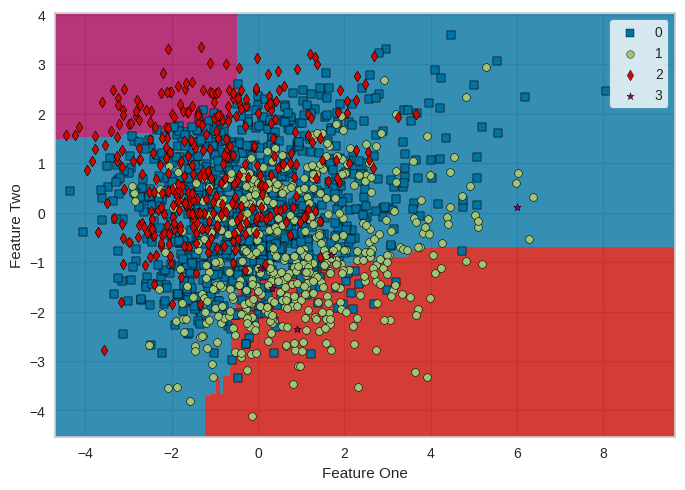

In [66]:
# <> --------------------------------------------------
# <> Visualizadno em forma de Gráfico
plot_model(rf_model, plot = 'boundary')

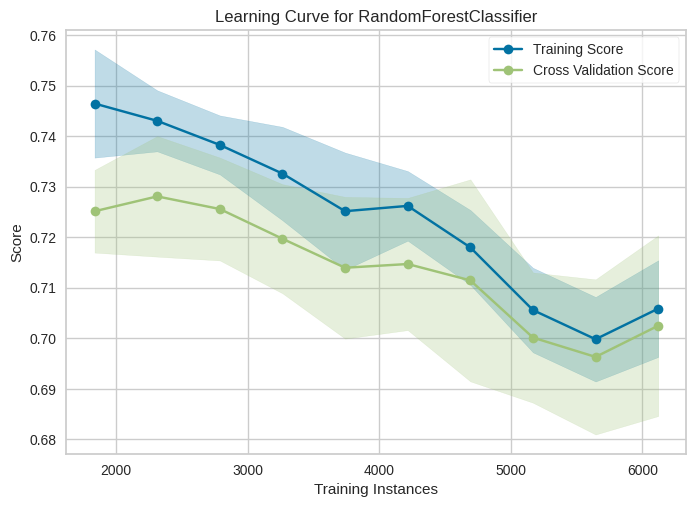

In [67]:
# <> ---------------------------------------------------
# <> Visualizando em forma de Gráfico
# <> cursva de aprendizado
plot_model(rf_model, plot = 'learning')

[Text(0.5, 0.875, 'chronotype_Night Owl <= 0.5\ngini = 0.61\nsamples = 4302\nvalue = [3570, 1883, 1325, 22]\nclass = Mild'),
 Text(0.25, 0.625, 'bedtime_hour <= 20.91\ngini = 0.59\nsamples = 2810\nvalue = [2471, 862, 1096, 3]\nclass = Mild'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'chronotype_Intermediate <= 0.5\ngini = 0.598\nsamples = 438\nvalue = [359, 241, 96, 3]\nclass = Mild'),
 Text(0.0625, 0.125, 'gini = 0.459\nsamples = 9\nvalue = [0, 9, 5, 0]\nclass = Moderate'),
 Text(0.1875, 0.125, 'gini = 0.593\nsamples = 429\nvalue = [359.0, 232.0, 91.0, 3.0]\nclass = Mild'),
 Text(0.375, 0.375, 'total_sleep_hours <= 8.005\ngini = 0.58\nsamples = 2372\nvalue = [2112, 621, 1000, 0]\nclass = Mild'),
 Text(0.3125, 0.125, 'gini = 0.525\nsamples = 2094\nvalue = [2112, 621, 564, 0]\nclass = Mild'),
 Text(0.4375, 0.125, 'gini = 0.0\nsamples = 278\nvalue = [0, 0, 436, 0]\nclass = No Debt'),
 Text(0.75, 0.625, 'bedtime_hour <= 0.995\ngini = 0.589\nsamples = 1492\nvalue = [1099.0, 1021.0

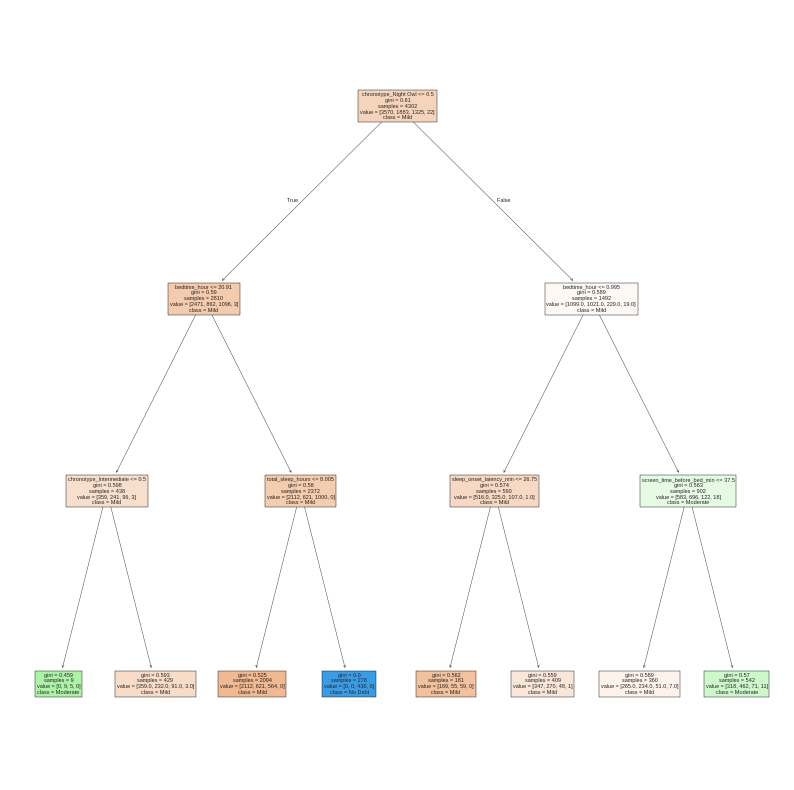

In [68]:
# <> ----------------------------------------------------
# <> Plotar UMA das árvores da floresta (a primeira)
# <> O Random Forest é um conjunto de árvores: rf_model.estimators_guarda todas elas
plt.figure(figsize=(10,10))
plot_tree(rf_model.estimators_[0], filled=True, feature_names=list(get_config('X_train').columns),
          class_names=sorted(y_train.unique()))

In [69]:
# <> -----------------------------------------------------
# <> Fazendo predição do modelo com os dados de teste do PyCaret
rf_testing_pred = predict_model(rf_model, data = test_data_pycaret)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.7229,0.8610,0.7229,0.8041,0.6780,0.4861,0.5567


Resumo das Métricas:

- **Accuracy**: Mede a taxa de acerto geral.

- **AUC**: Mede a capacidade de discriminação do modelo.

- **Recall**: Mede a capacidade de identificar positivos reais.

- **Precision**: Mede a confiabilidade das previsões positivas.

- **F1**: Equilibra Precision e Recall.

- **Kappa**: Mede a concordância ajustada ao acaso.

- **MCC**: Mede a correlação entre previsões e valores reais, robusta a desbalanceamentos.

In [70]:
# <> ----------------------------------------------------
# <> Visuaizando Cabeçalho do Data.Frame
rf_testing_pred.head()

,user_id,age,bedtime_hour,screen_time_before_bed_min,screen_brightness_pct,blue_light_filter_on,caffeine_intake_mg,caffeine_last_hour,physical_activity_min,room_temperature_f,...,occupation_Unemployed,primary_app_category_Gaming,primary_app_category_Messaging,primary_app_category_News,primary_app_category_Short-Form Video,primary_app_category_Social Media,primary_app_category_Streaming,sleep_debt_category,prediction_label,prediction_score
0,3001,16,0.940000,31,100,False,20,11.500000,30,69.500000,...,False,False,False,False,False,False,True,Mild,Mild,0.5578
1,7754,20,23.570000,31,27,True,56,10.400000,8,66.900002,...,False,False,False,False,True,False,False,Moderate,Mild,0.5763
2,3315,24,22.309999,45,51,True,43,10.900000,56,71.900002,...,False,False,False,False,False,True,False,No Debt,Mild,0.4530
3,7397,41,0.810000,133,100,True,30,18.299999,20,62.000000,...,False,False,False,False,False,False,True,Moderate,Moderate,0.6267
4,8202,40,0.920000,41,76,False,7,10.600000,35,61.599998,...,True,False,False,False,False,True,False,Mild,Mild,0.5595


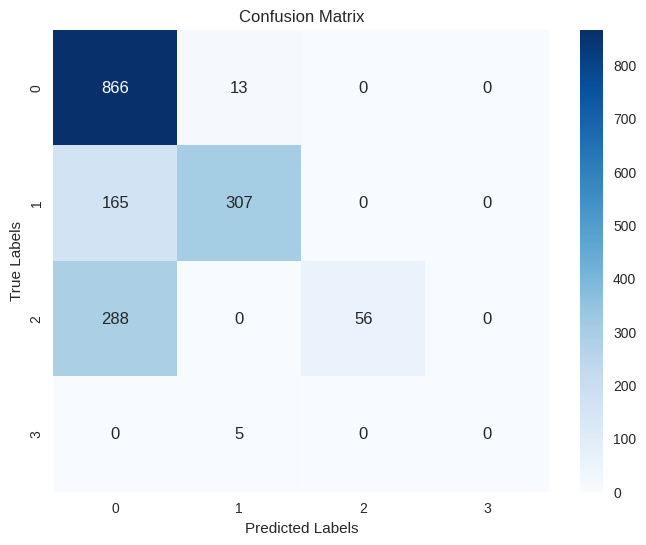

Acurácia: 0.7229411764705882
Kappa: 0.4860504449800537
Relatório de Classificação:
              precision    recall  f1-score   support

        Mild       0.66      0.99      0.79       879
    Moderate       0.94      0.65      0.77       472
     No Debt       1.00      0.16      0.28       344
      Severe       0.00      0.00      0.00         5

    accuracy                           0.72      1700
   macro avg       0.65      0.45      0.46      1700
weighted avg       0.80      0.72      0.68      1700



In [71]:
# <> Supondo que 'true_labels' seja a coluna de rótulos verdadeiros e 'predicted_labels' a coluna de rótulos previstos
true_labels = rf_testing_pred['sleep_debt_category']
predicted_labels = rf_testing_pred['prediction_label']

# Calcular a matriz de confusão
conf_matrix = confusion_matrix(true_labels, predicted_labels)

# Plotar a matriz de confusão
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Calcular acurácia
accuracy = accuracy_score(true_labels, predicted_labels)

# Calcular Kappa
kappa = cohen_kappa_score(true_labels, predicted_labels)

# Gerar relatporio de classificação
classification_rep = classification_report(true_labels, predicted_labels)

# Imprimir resultados
print(f'Acurácia: {accuracy}')
print(f'Kappa: {kappa}')
print('Relatório de Classificação:')
print(classification_rep)